# Пол клиента по транзакциям

| | ROC AUC | Accuracy |
|---|---|---|
| Кросс-валидация, train+val (2×5 фолдов) | 0.8907 ± 0.0121 | 0.8044 ± 0.0132 |
| **Test**, 1 680 клиентов, 95% CI | **0.898 [0.883; 0.913]** ✓ | **0.811 [0.793; 0.830]** ✓ |
| Требование задания | > 0.88 | > 0.80 |

**Подход**
1. Агрегаты клиента (профиль трат по MCC, суммы, время, динамика) + признаки с метками, считаемые out-of-fold → LightGBM.
2. Энкодер CoLES (GRU), предобученный без меток на последовательностях транзакций: эмбеддинг — признак для LightGBM, дообученный энкодер — отдельная модель.
3. TabPFN на 300 отобранных признаках; калиброванный бленд трёх моделей в пространстве логитов, порог 0.5.

**Содержание:** 1. Данные · 2. Признаки · 3. Модели · 4. Результат · 5. Выводы и ограничения

In [1]:
import json
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_auc_score

from gender_pred import cli, cv, data, features, plots
from gender_pred.cv import bootstrap_ci
from gender_pred.data import download_data, labels, load_config, prepare_events

RETRAIN = False  # True — полный пересчёт (~25 мин на GPU); False — финальные модели из artifacts/ (GitHub Release)
cfg = load_config("configs/default.yaml", retrain=RETRAIN)
plots.style()
pd.set_option("display.max_columns", 30, "display.width", 200)
download_data(cfg["paths"]["data"])  # данные с Hugging Face, если их ещё нет

## 1. Данные

Банковские карточные транзакции клиентов с меткой пола — открытый бенчмарк Сбербанка (используется,
например, в pytorch-lifestream / CoLES как задача gender); версия задания —
[`mks-logic/gender_prediction`](https://huggingface.co/datasets/mks-logic/gender_prediction): 8 400 клиентов,
разбитых на train / val / test **по клиентам**. Классифицируем **клиента**, а не транзакцию: у клиента одна
метка и история из десятков–тысяч операций. Всё, что касается меток, — только по train; метки test не
используются нигде.

| Колонка | Описание |
|---|---|
| `customer_id` | идентификатор клиента; по нему сделано разбиение на сплиты и агрегация признаков |
| `tr_datetime` | дата и время операции; даты условные: период с 2000-01-01, 457 дней |
| `day` | номер дня от начала периода; в этой версии CSV отдельной колонки нет — вычисляется из `tr_datetime` (раздел 2) |
| `mcc_code` | MCC — код категории продавца (продукты, одежда, авто, АЗС…), перекодирован в номера |
| `tr_type` | тип операции: покупка, снятие наличных, перевод, зачисление и т. д. |
| `amount` | сумма в условных единицах (отмасштабирована); **< 0 — расход, > 0 — поступление** |
| `term_id` | идентификатор терминала; пропуск (в шаблоне −1) — терминал неизвестен |
| `gender` | целевая метка: 0 — женщина, 1 — мужчина; одна на клиента |
| `tr_type_desc`, `mcc_code_desc` | текстовые описания типа операции и MCC; только для подписей |
| `gender_desc` | добавляется в `load_dataset` шаблона: метка словами |

**Сплиты и баланс классов** (метки — только train и val, обучающая выборка):

In [2]:
def load_dataset(splits=["train", "val", "test"], path="data/"):
    dataset = {}
    for split in splits:
        df = pd.read_csv(f"{path}{split}.csv")
        df["term_id"] = df["term_id"].fillna(-1)
        df['gender_desc'] = df.gender.map({0: "женщина", 1: "мужчина"})
        df['tr_datetime'] = pd.to_datetime(df['tr_datetime'], errors='coerce')
        df.sort_values(['customer_id', 'tr_datetime'], inplace=True)
        dataset[split] = df
    return dataset

dataset = load_dataset()

train_df = dataset["train"]
train_df.head(2)

,customer_id,tr_datetime,mcc_code,tr_type,amount,term_id,gender,tr_type_desc,mcc_code_desc,gender_desc
0,0,2000-01-01 10:23:26,0,0,-2245.92,-1,1,Оплата услуги. Банкоматы СБ РФ,"Звонки с использованием телефонов, считывающих...",мужчина
1,0,2000-01-02 10:19:29,1,1,56147.89,-1,1,Взнос наличных через АТМ (в своем тер.банке),Финансовые институты — снятие наличности автом...,мужчина


In [3]:
for split in ["train", "test", "val"]:
    print(f"{split.upper()} split: ", dataset[split]["customer_id"].nunique(), " customers")

TRAIN split:  5880  customers
TEST split:  1680  customers
VAL split:  840  customers


In [4]:
display(data.split_overview(dataset, label_splits=("train", "val")))
data.data_quality(train_df).to_frame("качество train")

,строк,клиентов,начало,конец,дней,доля мужчин
train,2613040,5880,2000-01-01,2001-04-01,457,0.439
val,383675,840,2000-01-01,2001-04-01,457,0.425
test,754368,1680,2000-01-01,2001-04-01,457,—


,качество train
строк,2613040
полных дубликатов строк,7658
нераспознанных дат (NaT),0
клиентов с > 1 значением пола,0
|amount|: 99-й перцентиль,1122957.89
|amount|: 99.9-й перцентиль,4941014.7
|amount|: максимум,145984525.17
доля операций с |amount| > 99.9-го перцентиля,0.001


**Вывод.** 2.6 млн операций у 5 880 клиентов train; мужчин 44% (в val 43%) — классы почти сбалансированы,
порог 0.5 и accuracy адекватны. Данные чистые: все даты распознаются, у каждого клиента одно значение пола.
0.3% строк — полные дубликаты (вероятно, реальные повторные операции); одинаково обрабатываются на всех
сплитах, не удаляются. Суммы с тяжёлыми хвостами (максимум ≈ 30 × 99.9-й перцентиль) → в признаках
log(1 + |amount|) и квантили.

**Что покупает клиент.** MCC с наибольшим отклонением доли мужчин от средней (train, MCC с ≥ 200 клиентами,
95% интервалы Уилсона):

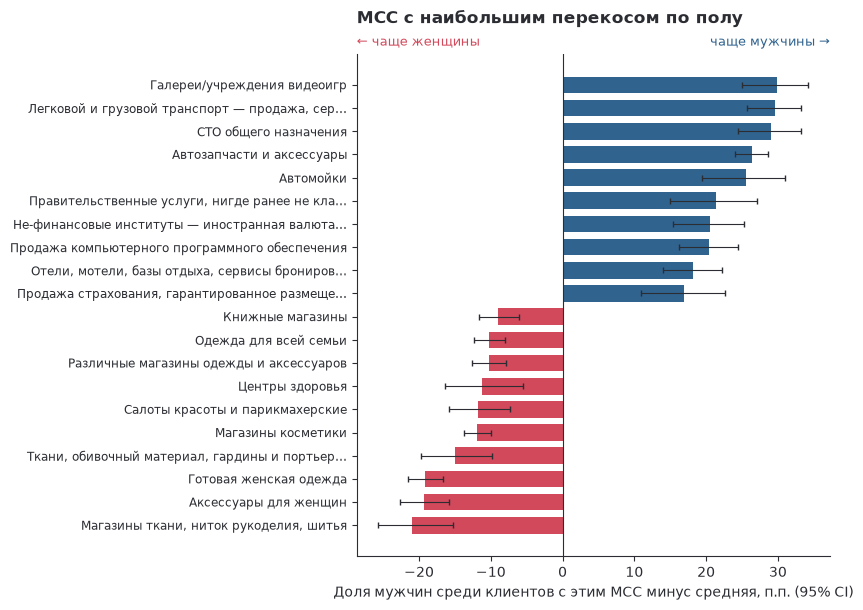

In [5]:
fig = plots.mcc_gender_skew(cfg)

In [6]:
def plot_top_counts(series, top_n=20, xlabel="Count", ylabel=""):
    counts = series.value_counts()
    top_items = counts.nlargest(top_n)
    plt.figure(figsize=(8,6))
    plt.barh(top_items.index, top_items.values)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.show()

**Вывод.** Перекос сильный и интерпретируемый: «Галереи/учреждения видеоигр» — доля мужчин на
30 п.п. выше средней, «Магазины ткани, ниток рукоделия, шитья» — на 21 п.п. ниже;
интервалы не пересекают ноль. Самый сильный перекос — в редких категориях (из 184 MCC семь самых частых
покрывают 80% операций), поэтому профиль строится по всем MCC, а не только по частым.

**Когда покупает.** Доля операций по часам (операции со временем 00:00:00 исключены — см. ниже):

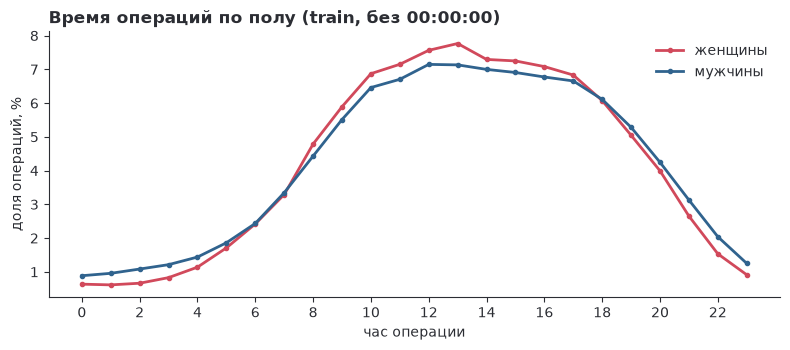

In [7]:
fig = plots.hourly_by_gender(train_df)

У мужчин больше операций вечером и ночью, у женщин — днём: различие небольшое, но стабильное →
часовой профиль, доли ночных / вечерних операций, дни недели (7 долей по `day % 7`).

**Проверка: время 00:00:00.**

In [8]:
summary, by_type = data.midnight_check(train_df)
display(summary.to_frame("train"))
by_type

,train
операций в 00:00:00,316243
в среднем за секунду 00:00:01–00:00:59,4.9
в среднем за секунду суток,30.2
доля операций в 00:00:00,0.121


,desc,операций,доля_00,доля всех 00:00:00
tr_type,,,,
6,Покупка. POS ТУ Россия,361872,0.629,0.720
9,Покупка. ТУ Россия,44599,0.737,0.104
25,Покупка. Зарубеж. ТУ,33919,0.936,0.100
7,Возврат покупки. POS ТУ Россия,7677,0.802,0.019
26,Покупка. POS Зарубеж. ТУ,8831,0.690,0.019


**Вывод.** 12% операций — ровно 00:00:00, в десятки тысяч раз больше, чем на соседние секунды; 72% из них —
один тип «Покупка. POS ТУ Россия» (и родственные «ТУ» / зарубежные): для этих каналов время не передаётся.
Это «время неизвестно», а не полночь → флаг `mid`, такие операции исключаются из часового профиля, их доля —
отдельный признак.

**Проверка: масштаб сумм.**

In [9]:
unit, in_units = data.amount_scale(train_df)
rs = data.round_share(train_df, unit)
y_tr = labels(train_df)
print(f"самая частая |amount| = {unit}; |amount| в этих единицах (топ-8):", in_units.head(8).to_dict())
print(f"доля операций с целым числом единиц: {(rs * train_df.groupby('customer_id').size()).sum() / len(train_df):.1%}")
print(f"AUC доли «круглых» операций клиента как единственного признака (train): {roc_auc_score(y_tr, rs.reindex(y_tr.index)):.3f}")

самая частая |amount| = 2245.92; |amount| в этих единицах (топ-8): {1.0: 161214, 10.0: 101500, 5.0: 92706, 0.5: 80873, 2.0: 74688, 20.0: 61565, 3.0: 53259, 30.0: 49310}
доля операций с целым числом единиц: 42.5%
AUC доли «круглых» операций клиента как единственного признака (train): 0.524


**Вывод.** Суммы — исходные суммы × константа ≈ 2245.92: в этих единицах значения 1, 10, 5, 0.5, 2, 20…,
и 42.5% операций — целое число единиц. «Круглые» суммы восстановимы, но доля круглых операций клиента
почти не связана с полом (AUC 0.524) → такого признака в модели нет.

**Проверка: терминалы** (пересечение train / test — без меток test).

In [10]:
data.terminal_overview(train_df, dataset["test"]).to_frame("значение")

,значение
терминалов в train,245165
"клиентов на терминал, медиана",1
доля терминалов с одним клиентом,0.698
доля операций test на терминалах из train,0.704
доля клиентов test с хотя бы одним терминалом из train,0.993


**Вывод.** У медианного терминала один клиент, 70% терминалов — у одного клиента; общие с test терминалы —
в основном крупные сети с клиентами обоих полов; у 41% операций терминала нет. Терминалы — слабая группа из
нескольких общих статистик; target encoding терминалов и граф клиент–терминал не дали прироста.

**Проверка: похож ли test на train** — adversarial validation: LightGBM отличает клиентов train от клиентов
test по агрегатам без меток (5 фолдов; посчитано в пакете, `cv.adversarial_auc`).

In [11]:
adv = json.loads(Path("results/adversarial_validation.json").read_text())
print(f"train ({adv['n_a']}) vs test ({adv['n_b']}): AUC = {adv['auc']:.3f} ± {adv['auc_std']:.3f}")

train (5880) vs test (1680): AUC = 0.495 ± 0.017


AUC ≈ 0.5 — сплиты неразличимы, сдвига нет; клиентов в нескольких сплитах нет → кросс-валидация на
train + val репрезентативна для test.

**Наблюдение → решение → чем подтверждено**

| Наблюдение | Решение в пайплайне | Чем подтверждено |
|---|---|---|
| Классификация клиента; разбиение по клиентам | всё агрегируется до клиента; CV — stratified по клиентам на train + val | общих клиентов у сплитов нет |
| Test не отличается от train | CV на train + val как оценка качества; test — один раз | adversarial AUC = 0.495 |
| 12% операций в 00:00:00 — время не передаётся для части каналов | флаг `mid`, исключение из часового профиля, доля — признак | 72% таких операций — один тип |
| Недельный цикл, неизвестно, какие дни выходные | 7 долей по `day % 7` вместо флага «выходной» | доли операций по `day % 7` различаются |
| Активность различается на порядки; хвосты сумм тяжёлые | доли вместо счётчиков; log(1 + \|amount\|), квантили; отдельно расходы и поступления | максимум ≈ 30 × p99.9 |
| Суммы = исходные × константа | без признака «круглая сумма» | AUC доли круглых = 0.524 |
| Сильнейший перекос — в редких MCC | доли по всем 184 MCC, TF-IDF + логрег, сглаженный target encoding | интервалы Уилсона; AUC группы MCC = 0.874 (раздел 2) |
| Один клиент на терминал | только общие статистики терминалов | TE терминалов и граф — в пределах шума по 10 фолдам |

## 2. Признаки

**Подготовка транзакций.** `prepare_events` переводит сырые строки в компактный вид, общий для агрегатов
и последовательной модели. Три операции одного клиента до и после (последняя — со временем 00:00:00):

In [12]:
one = train_df[train_df["customer_id"] == train_df["customer_id"].iloc[0]]
at_midnight = one["tr_datetime"] == one["tr_datetime"].dt.normalize()
rows = pd.concat([one[~at_midnight].head(2), one[at_midnight].head(1)])
display(rows[["customer_id", "tr_datetime", "mcc_code", "tr_type", "amount", "term_id"]])
prepare_events(rows)[["cid", "mcc", "tt", "la", "out", "term", "day", "hour", "dow", "mid"]]

,customer_id,tr_datetime,mcc_code,tr_type,amount,term_id
0,0,2000-01-01 10:23:26,0,0,-2245.92,-1
1,0,2000-01-02 10:19:29,1,1,56147.89,-1
28,0,2000-01-16 00:00:00,8,6,-6288.56,-1


,cid,mcc,tt,la,out,term,day,hour,dow,mid
0,0,0,0,7.717316,True,-1,0,10,0,False
1,0,1,1,10.935762,False,-1,1,10,1,False
2,0,8,6,8.746646,True,-1,15,0,1,True


`la` = log(1 + |amount|), `out` — расход, `day` — номер дня, `hour` / `dow` — час и день недели, `mid` — время
неизвестно. Для последовательной модели дополнительно — знаковая лог-сумма и логарифм интервала до
предыдущей операции.

**Признаки клиента.** Энкодер CoLES нужен уже здесь — его эмбеддинг входит в признаки. При `RETRAIN = False`
энкодер и финальные модели загружаются из `artifacts/` (архив из GitHub Release), при `True` — обучаются
заново. Функции шаблона — тонкие обёртки над пакетом: `generate_features` считает признаки одного сплита,
`fit_predict_proba` обучает на train + val и предсказывает test.

In [13]:
def generate_features(df):
    """Агрегаты клиента + эмбеддинг CoLES (index = customer_id); последовательности — в хранилище пакета."""
    X = ctx.features(df)
    y = labels(df).reindex(X.index)
    return X, y


def fit_predict_proba(X_train, y_train, X_val, y_val, X_test):
    """LightGBM + дообученный CoLES + TabPFN, калиброванный бленд; порог 0.5."""
    return cli.fit_predict(ctx, X_train, y_train, X_val, y_val, X_test)

In [14]:
ctx = cli.build_context(cfg, dataset, log=False)
print(f"устройство: {ctx.device}; клиентов с последовательностями: {len(ctx.seqs.ids)}")
X_train, y_train = generate_features(dataset["train"])
print("X_train:", X_train.shape)
features.feature_groups(X_train)

устройство: cuda; клиентов с последовательностями: 8400


X_train: (5880, 2165)


,группа,префикс,признаков,примеры
0,Активность,act_,16,"act_n_tr, act_n_tt, act_gap_mean"
1,Суммы,amt_,31,"amt_out_cnt, amt_out_la_q75, amt_in_la_skew"
2,MCC-профиль,mcc_,408,"mcc_cnt_0, mcc_cnt_136, mcc_sum_88"
3,Типы операций,tt_,148,"tt_cnt_0, tt_cnt_49, tt_sum_24"
4,Время,time_,48,"time_hour_0, time_hour_16, time_dow_sum_1"
5,Терминалы,term_,7,"term_na_share, term_tr_per_term, term_top3_share"
6,Динамика,dyn_,41,"dyn_mcc_cnt_hhi, dyn_out_frac_ewm30, dyn_w30_o..."
7,Счётчики,raw_,442,"raw_mcccnt_0, raw_mcccnt_147, raw_mccsum_110"
8,Эмбеддинги CoLES,emb_,1024,"emb_0, emb_341, emb_682"


Колонки одинаковы на любом сплите: словари MCC и типов операций фиксируются по train. `raw_` — счётчики по
каждому MCC / типу (вход для признаков с метками, в бустинг напрямую не идут), `emb_` — эмбеддинг CoLES.

**Признаки с метками** — target encoding MCC и типов операций, логрег по TF-IDF профиля трат, логрег по
эмбеддингу CoLES. Посчитанные по всем клиентам, они «видели» бы метку самого клиента — утечка. Поэтому они
считаются **out-of-fold**: значение обучающего клиента считает модель, обученная на остальных 4/5 обучающих
клиентов; для новых клиентов (фолд валидации, test) — по статистикам всех обучающих. Test в расчёте не
участвует. Тот же расчёт на train, AUC ключевых признаков в одиночку — по клиентам, у которых признак
определён (покрытие < 100%: например, разброс target encoding не определён при одной категории):

In [15]:
lf = features.LabelFeatures(cfg["features"], seed=0, n_inner=cfg["cv"]["inner_splits"])
L_train = lf.fit_transform(X_train, y_train)
key = ["te_mcc_wmean", "te_mcc_lo_mean", "te_mcc_std", "te_tt_wmean", "lr_tfidf", "lr_emb"]
pd.DataFrame(
    {c: {"OOF AUC на train": roc_auc_score(y_train[L_train[c].notna()], L_train[c].dropna()),
         "покрытие, %": 100 * L_train[c].notna().mean()} for c in key}
).T.round({"OOF AUC на train": 3, "покрытие, %": 1})

,OOF AUC на train,"покрытие, %"
te_mcc_wmean,0.785,100.0
te_mcc_lo_mean,0.816,100.0
te_mcc_std,0.630,99.1
te_tt_wmean,0.566,100.0
lr_tfidf,0.861,100.0
lr_emb,0.857,100.0


**Сила сигнала групп признаков без меток:** LightGBM на каждой группе отдельно (5 фолдов на train + val,
число деревьев — по остальным фолдам; посчитано в пакете, `cv.group_signal`).

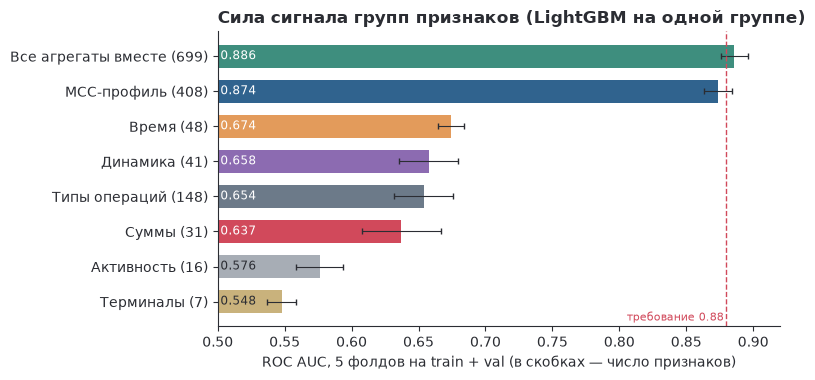

In [16]:
fig = plots.group_signal(cfg)

**Вывод.** Одна группа MCC-профиля даёт AUC 0.874, все агрегаты вместе — 0.886;
остальные группы по отдельности слабые (0.55–0.67), но вместе с MCC добавляют +0.012.
Признаки с метками сжимают профиль трат в несколько сильных чисел (логрег по TF-IDF — AUC ≈ 0.86).

## 3. Модели

Три модели смотрят на клиента по-разному: **LightGBM** на агрегатах — сильнейшая одиночная модель;
**TabPFN** на тех же признаках — другой способ обобщения (предобученный трансформер вместо деревьев);
**CoLES**, дообученный на пол, видит порядок и ритм операций, которых нет в агрегатах. XGBoost вровень
с LightGBM, прирост в бленде в пределах шума — оставили одну модель бустинга ради простоты; CatBoost хуже,
вес 0. Веса бленда подбираются по out-of-fold предсказаниям; на CV калибровка, веса и число деревьев для
фолда — по остальным фолдам, поэтому метрики ниже честные. Ниже — схема, сводная таблица моделей
и гиперпараметры всех моделей из `configs/default.yaml`.

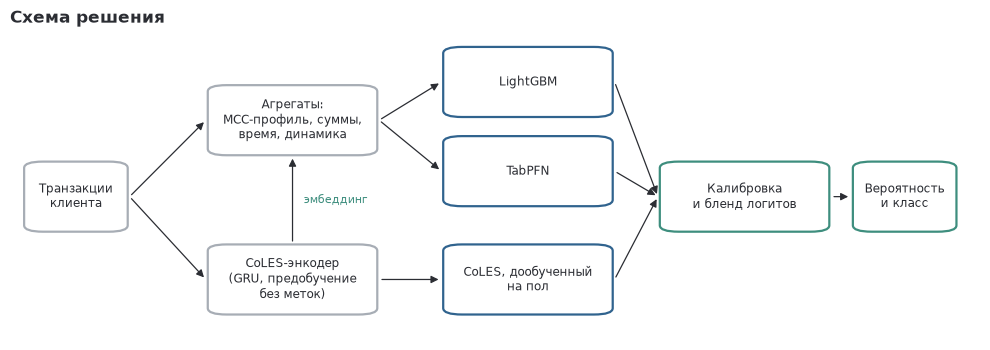

In [17]:
fig = plots.pipeline_schema()

In [18]:
with pd.option_context("display.max_colwidth", None):
    display(cv.model_summary("results"))

,что это,на чём учится,CV ROC AUC,CV accuracy,в финале
модель,,,,,
LightGBM,"градиентный бустинг, основная модель","агрегаты клиента + признаки с метками (OOF), в т. ч. логрег по эмбеддингу CoLES",0.8900 ± 0.0119,0.8028 ± 0.0127,"да, вес 0.70"
TabPFN v2,"предобученный трансформер для таблиц, предсказывает без обучения деревьев","300 признаков, отобранных по gain LightGBM внутри обучения",0.8874 ± 0.0124,0.8001 ± 0.0132,"да, вес 0.20"
"CoLES, дообученный","GRU-энкодер, предобученный контрастно без меток, + голова на пол",последовательность последних 1 200 транзакций клиента,0.8664 ± 0.0135,0.7815 ± 0.0144,"да, вес 0.10"
XGBoost,градиентный бустинг,"та же матрица и те же фолды, что у LightGBM",0.8898 ± 0.0126,0.8042 ± 0.0131,"нет: вровень с LightGBM (AUC -0.0001 ± 0.0018 к LightGBM, лучше в 7/10 фолдов); прирост в бленде +0.00003 ± 0.0006 AUC — в пределах шума, оставили одну модель бустинга ради простоты"
CatBoost,градиентный бустинг (симметричные деревья),"та же матрица и те же фолды, что у LightGBM",0.8853 ± 0.0129,0.7972 ± 0.0161,"нет: хуже LightGBM (AUC -0.0047 ± 0.0027 к LightGBM, лучше в 0/10 фолдов); в бленде вес 0"
Бленд = итог,калиброванная взвешенная сумма логитов трёх моделей,"out-of-fold предсказания LightGBM, TabPFN и CoLES",0.8907 ± 0.0121,0.8044 ± 0.0132,"итог, порог 0.5"


In [19]:
with pd.option_context("display.max_colwidth", None):
    display(cv.hyperparameter_table(cfg))
print(ctx.encoder)
print(f"параметров энкодера: {sum(p.numel() for p in ctx.encoder.parameters()):,}".replace(",", " "))

значение                                              как выбран
модель              параметр                                                                                                                                                      
LightGBM            learning_rate / num_leaves / min_child_samples                                          0.02 / 15 / 30                         фиксировано (Optuna не улучшил)
                    feature_fraction / bagging_fraction / lambda_l2                                      0.25 / 0.8 / 10.0                         фиксировано (Optuna не улучшил)
                    число деревьев                                                                  ≤ 3000, сетка шагом 50  вложенно: максимум средней AUC-кривой остальных фолдов
                    деревьев в финальной модели                                                   среднее по фолдам × 1.25                           поправка на 25% больше данных
CoLES, энкодер      GRU hidden / MCC emb / tr_type emb                                                      1024 / 48 / 24               эталонный конфиг CoLES (ptls-experiments)
                    шум эмбеддингов категорий                                                                        0.003               эталонный конфиг CoLES (ptls-experiments)
CoLES, предобучение оптимизатор, lr                                                                            Adam, 0.002               эталонный конфиг CoLES (ptls-experiments)
                    шедулер                                                                StepLR: каждые 10 эпох × 0.9025               эталонный конфиг CoLES (ptls-experiments)
                    эпох / батч клиентов                                                                          50 / 128                    эпохи — по плато качества эмбеддинга
                    срезов на клиента / длина среза                                                     5 / 15–75 операций               эталонный конфиг CoLES (ptls-experiments)
                    loss                                             контрастная: margin 0.5, 5 трудных негативов на якорь               эталонный конфиг CoLES (ptls-experiments)
                    dropout транзакций                                                                                0.01               эталонный конфиг CoLES (ptls-experiments)
CoLES, дообучение   lr энкодера / головы                                                             0.0001 / 0.005 (Adam)                                    по CV на train + val
                    шедулер / эпох / батч                                              StepLR: каждую эпоху × 0.4 / 8 / 32                                    по CV на train + val
                    длина среза / история при предсказании                               250–350 / последние 1200 операций                                    по CV на train + val
                    dropout транзакций                                                                                0.01               эталонный конфиг CoLES (ptls-experiments)
TabPFN v2           признаков                                                  300, отбор по gain LightGBM внутри обучения                         лимит TabPFN на число признаков
                    ансамблей (n_estimators)                                                                             8                                            по умолчанию
Бленд               калибровка                                                          Platt для каждой модели и итоговый                            по out-of-fold предсказаниям
                    веса                                                                  симплекс, шаг 0.05, максимум AUC                     по OOF; на CV — по остальным фолдам
                    порог                                                                                              0.5                  калиброванные вероятности, без подбо

Encoder(
  (e_mcc): NoisyEmbedding(185, 48, padding_idx=0)
  (e_tt): NoisyEmbedding(75, 24, padding_idx=0)
  (e_hour): Embedding(25, 8)
  (e_dow): Embedding(7, 4)
  (gru): GRU(86, 1024, batch_first=True)
)
параметров энкодера: 3 427 996


**Калибровка и веса бленда** финальной модели (Platt: logit → a·logit + b; затем взвешенная сумма
и итоговый Platt), затем **Optuna**: вложенный тюнинг LightGBM — в каждом внешнем фолде свой поиск на
внутренних фолдах его обучающей части и проверка на внешнем фолде против базовых параметров.

In [20]:
model_dir = ctx.artifacts / "model"
if (model_dir / "model.json").exists():
    blend = cv.GenderModel.load(model_dir, cfg, ctx.device, ctx.seqs).blend_
    display(blend.describe(cfg["blend"]["components"]).round(4))
else:
    print("модель ещё не обучена: при RETRAIN = True она появится после ячейки шаблона в разделе 4")

,a,b,вес
шаг,,,
Platt: gbm,0.9398,0.0066,0.7
Platt: seq,0.9462,0.0921,0.1
Platt: tabpfn,0.8617,-0.0762,0.2
итоговый Platt,1.0311,0.0087,NaN


In [21]:
hp = json.loads(Path("results/hyperparameter_search.json").read_text())
print(f"{hp['n_trials']} trials на фолд; {hp['outer_folds_note']}")
pd.DataFrame({"базовые параметры": hp["outer_auc_base"], "Optuna": hp["outer_auc_optuna"]},
             index=pd.Index(hp["outer_folds"], name="внешний фолд")).assign(
    **{"Δ": lambda d: d["Optuna"] - d["базовые параметры"]}).round(4)

50 trials на фолд; проверено на 5 внешних фолдах из 10 (повтор 0); остановлено досрочно — прироста нет


,базовые параметры,Optuna,Δ
внешний фолд,,,
r0k0,0.8889,0.8899,0.0010
r0k1,0.9011,0.8989,-0.0021
r0k2,0.8845,0.8784,-0.0061
r0k3,0.9021,0.8999,-0.0022
r0k4,0.8763,0.8782,0.0019


**Вывод.** На внутренних фолдах Optuna находит параметры чуть лучше (+0.0004…+0.0020),
на внешних — нет: Δ AUC = -0.0015 ± 0.0031, лучше в 2 из 5
фолдов — подстройка под внутреннюю валидацию. Используются базовые параметры. По 10 фолдам CV итоговый бленд
даёт AUC от 0.874 до 0.913 (2 фолда ниже 0.88), поэтому каждое
изменение модели принималось только по парному сравнению на тех же фолдах.

## 4. Результат

Бейзлайн задания (RandomForest на 4 агрегатах), затем ячейка шаблона с финальной моделью: признаки
считаются на каждом сплите отдельно, модель обучается на train + val, test только предсказывается.

In [22]:
def baseline_aggregation(df):
    tx_stats = df.groupby('customer_id').agg({
        'amount': ['count', 'sum'],
        'mcc_code': pd.Series.nunique,
        'tr_type': pd.Series.nunique,
    })
    tx_stats.columns = [f'base_{k}_{stat}' for k, stat in tx_stats.columns]
    tx_stats.reset_index(inplace=True)

    target = df[['customer_id', 'gender']].drop_duplicates()
    features = tx_stats.merge(target, on='customer_id', how='left')

    X = features.drop(columns=['customer_id', 'gender'])
    y = features['gender']

    return X, y

X_train, y_train = baseline_aggregation(dataset["train"])
X_test, y_test = baseline_aggregation(dataset["test"])
X_val, y_val = baseline_aggregation(dataset["val"])

assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]

In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, accuracy_score, average_precision_score,
    precision_score, recall_score
)

def eval(y_val, y_pred, y_pred_proba):
    auc = roc_auc_score(y_val, y_pred_proba)
    acc = accuracy_score(y_val, y_pred)
    precision = precision_score(y_val, y_pred)
    recall = recall_score(y_val, y_pred)

    return {
        "auc_score": auc,
        "accuracy_score": acc,
        "precision_score": precision,
        "recall_score": recall
    }

def fit_predict_rf(X_train, y_train, X_val, y_val, X_test):
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    y_pred_proba = model.predict_proba(X_test)[:, 1]
    y_pred = (y_pred_proba >= 0.5).astype(int)

    return y_pred_proba, y_pred

y_pred_proba, y_pred = fit_predict_rf(X_train, y_train, X_val, y_val, X_test)
metrics = eval(y_test, y_pred, y_pred_proba)
metrics

{'auc_score': 0.5737087280045527,
 'accuracy_score': 0.5577380952380953,
 'precision_score': 0.5238095238095238,
 'recall_score': 0.4269081500646831}

In [24]:
# Feature engineering
X_train, y_train = generate_features(dataset["train"])
X_test, y_test = generate_features(dataset["test"])
X_val, y_val = generate_features(dataset["val"])

assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]

# Model training and prediction
y_pred_proba, y_pred = fit_predict_proba(X_train, y_train, X_val, y_val, X_test)

# Evaluation
metrics = eval(y_test, y_pred, y_pred_proba)
metrics

{'auc_score': 0.8979020440415284,
 'accuracy_score': 0.8113095238095238,
 'precision_score': 0.8343108504398827,
 'recall_score': 0.7360931435963778}

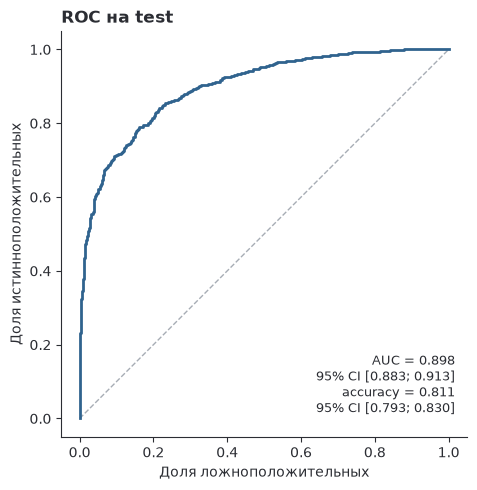

In [25]:
m = bootstrap_ci(y_test.to_numpy(), y_pred_proba, threshold=0.5, n=cfg["report"]["bootstrap"])
pd.DataFrame({"gender": y_test.to_numpy(), "proba": y_pred_proba}, index=y_test.index).to_parquet(
    "results/test_predictions.parquet")
fig = plots.roc_test(cfg)

На test AUC = **0.8979** (95% CI 0.883–0.913), accuracy = **0.8113**
(95% CI 0.793–0.830): требования ✓ AUC > 0.88 и
✓ accuracy > 0.80. Бейзлайн задания — AUC 0.574.

**Вклад компонентов** (кросс-валидация):

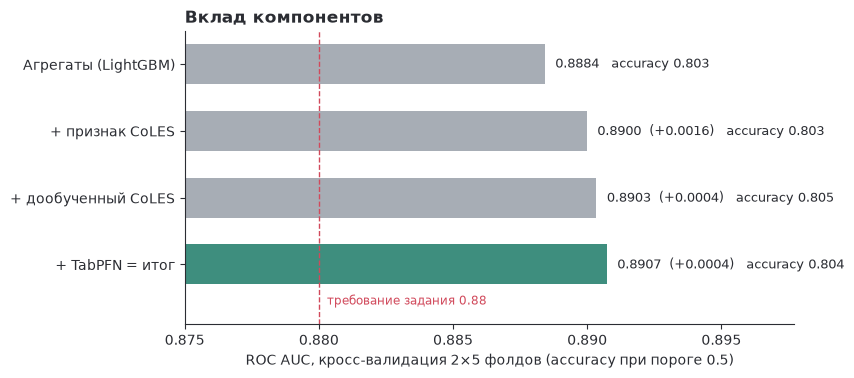

In [26]:
fig = plots.component_contribution(cfg)

Агрегаты с LightGBM дают 0.8884; признак CoLES, дообученный CoLES и TabPFN добавляют
по +0.0004…+0.0016 — каждое добавление проверено парным сравнением по 10 фолдам; итог 0.8907.

## 5. Выводы и ограничения

- Главный сигнал — **профиль трат по MCC** (одна группа — AUC 0.874); остальные агрегаты, CoLES и
  TabPFN добавляют ещё ≈ 0.017.
- **CoLES** полезен как дополнение к агрегатам (эмбеддинг-признак и дообученная модель в бленде), но не как
  замена: на 8 400 клиентах предобучению не хватает объёма неразмеченных последовательностей.
- **Калиброванный бленд** даёт честные вероятности → порог 0.5 без подбора на test; test открыт один раз:
  AUC 0.8979, accuracy 0.8113.
- **Шум test**: 95% интервал AUC ≈ ±0.015 — шире различий между сильными вариантами модели; запас по accuracy
  небольшой (CV 0.804, в 4 из 10 фолдов ниже 0.80).
- **Разбиение по клиентам, а не по времени**: для продакшена нужны out-of-time валидация и мониторинг дрейфа
  (PSI по ключевым признакам и по скорам).
- Проверено и не вошло: target encoding по терминалам и граф клиент–терминал, XGBoost и CatBoost, тюнинг
  Optuna, признак «круглых» сумм — в пределах шума.